# RAG: Baseline (Bi-Encoder) vs. Re-Ranking (Cross-Encoder)

**Document:** HDFC ERGO *my: Optima Secure* — Policy Wording (53 pages, health-insurance contract).
Insurance wordings are a hard retrieval target: dozens of near-identical clauses, long exclusion lists,
"unless / except" carve-outs, and product-specific numbers an LLM cannot know from memory.

| Component | Choice |
|---|---|
| PDF parsing | PyMuPDF, header/footer clipped by page coordinates |
| Chunking | token-aware, 200 tokens, 40-token overlap, line-boundary aligned |
| Bi-encoder | `sentence-transformers/all-MiniLM-L6-v2` (384-d) |
| Vector store | FAISS `IndexFlatIP` on L2-normalised vectors (= cosine similarity) |
| Cross-encoder | `cross-encoder/ms-marco-MiniLM-L-6-v2` |
| LLM | Gemini `gemini-3.1-flash-lite`, temperature 0, identical prompt for both pipelines |
| Answer grading | blind LLM judge (`gemini-3.8-flash`) + manual review |

**Pipeline 1 (Baseline):** query → bi-encoder → top-10 by cosine → top-3 → LLM → *Answer 1*
**Pipeline 2 (Re-rank):** same top-10 → cross-encoder scores 10 (query, chunk) pairs → re-sort → top-3 → LLM → *Answer 2*

**Notebook map**
1. Setup · 2. Load & clean PDF · 3. Chunking · 4. Index · 5. Pipelines · 6. LLM generation
7. Stress tests (failure modes) · 8. Answer 1 vs Answer 2 · 9. Aggregate evaluation (~115 labelled queries)
10. Score distributions · 11. Latency profiling · 12. Scaling experiment · 13. Limitations · 14. Summary

## 1. Setup

In [1]:
# Dependencies (uncomment on a fresh environment):
# !pip install pymupdf sentence-transformers faiss-cpu google-genai python-dotenv pandas matplotlib

import os, re, json, time, platform, warnings
os.environ["TOKENIZERS_PARALLELISM"] = "false"
warnings.filterwarnings("ignore")              # silence library deprecation/progress warnings in the output
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymupdf                      # PyMuPDF
import faiss
import torch
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()   # hide model-loading reports
from dotenv import load_dotenv
from google import genai
from google.genai import types

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(4)   # i7-1360P has 4 performance cores; 4 threads gave the fastest, most stable timings

# ---- Configuration --------------------------------------------------------------------
PDF_PATH        = "optima-secure-revision-pw.pdf"
BI_ENCODER      = "sentence-transformers/all-MiniLM-L6-v2"
CROSS_ENCODER   = "cross-encoder/ms-marco-MiniLM-L-6-v2"
LLM_MODEL       = "gemini-3.1-flash-lite"  # generates Answer 1 and Answer 2 (same model for every query)
LLM_FALLBACK    = "gemini-3.5-flash-lite"  # used only if the main model keeps failing
JUDGE_MODEL     = "gemini-3.8-flash"       # grades answers; a different, larger model than the generator
JUDGE_FALLBACK  = "gemini-flash-latest"
CHUNK_TOKENS    = 200    # MiniLM truncates input at 256 word-pieces -> keep every chunk below it
OVERLAP_TOKENS  = 40     # carry ~2 lines over so a clause split at a boundary appears in both chunks
TOP_K_RETRIEVE  = 10     # candidates from the bi-encoder
TOP_N_CONTEXT   = 3      # chunks given to the LLM
HEADER_Y, FOOTER_Y = 100, 788   # PDF points: everything above/below is the repeated letterhead/footer

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

load_dotenv(".env")                       # GEMINI_API_KEY lives in .env (git-ignored)
llm_client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])

print("Python", platform.python_version(), "| torch", torch.__version__, "| faiss", faiss.__version__)
print("CPU:", platform.processor() or platform.machine(), "| torch threads:", torch.get_num_threads())

Python 3.10.12 | torch 2.11.0+cu130 | faiss 1.13.2
CPU: x86_64 | torch threads: 4


In [2]:
# Shared plot style: blue = Baseline (bi-encoder), orange = Re-ranked (cross-encoder).
BASE_C, RERANK_C = "#2a78d6", "#eb6834"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "legend.frameon": False, "figure.dpi": 110,
})

## 2. Load & clean the PDF
Every page carries a 4-line letterhead and a 3-line registered-office footer with the page number.
Left in, these lines would appear in all 176 chunks and pull every embedding toward the same point,
so they are removed by **clipping the page to the body region** (y = 100…788 pt). Page 1 (table of
contents) is skipped because it only repeats section titles.

In [3]:
def load_policy_lines(path):
    # Return [(page_no, line_text), ...] for the body text of every page.
    doc = pymupdf.open(path)
    lines = []
    for page_no, page in enumerate(doc, start=1):
        if page_no == 1:                                    # table of contents
            continue
        body = pymupdf.Rect(0, HEADER_Y, page.rect.width, FOOTER_Y)
        for raw in page.get_text("text", clip=body).splitlines():
            text = re.sub(r"\s+", " ", raw).strip()        # collapse layout whitespace
            if text:
                lines.append((page_no, text))
    return lines, doc.page_count

lines, n_pages = load_policy_lines(PDF_PATH)
print(f"{n_pages} pages -> {len(lines)} body lines, {sum(len(t.split()) for _, t in lines):,} words")
for p, t in lines[:6]:
    print(f"  p{p:>2} | {t}")

53 pages -> 2944 body lines, 20,310 words
  p 2 | Preamble
  p 2 | This Policy is a contract of insurance issued by HDFC ERGO General Insurance Company Limited
  p 2 | (hereinafter called the ‘Company’) to the proposer mentioned in the Policy Schedule (hereinafter called the
  p 2 | ‘Policyholder’) to cover the person(s) named in the Policy Schedule (hereinafter called the ‘Insured
  p 2 | Person(s)’). The Policy is based on the statements and declaration provided by the Policyholder in the
  p 2 | Proposal Form as well as in any welcome or other tele-verification calls with the Company’s authorized


## 3. Chunking
Lines are packed greedily into chunks of ≤ 200 **MiniLM word-piece tokens**, never splitting a line,
with the last ~40 tokens repeated at the start of the next chunk. Counting tokens with the
bi-encoder's own tokenizer guarantees no chunk is silently truncated at the model's 256-token limit.
Both pipelines use this **exact same corpus**.

In [4]:
bi_encoder = SentenceTransformer(BI_ENCODER, device="cpu")
tokenizer = bi_encoder.tokenizer
n_tok = lambda s: len(tokenizer.tokenize(s))

def chunk_lines(lines, max_tokens=CHUNK_TOKENS, overlap_tokens=OVERLAP_TOKENS):
    chunks, cur, cur_tok = [], [], 0

    def emit(buf):
        chunks.append({"page": buf[0][0], "page_end": buf[-1][0],
                       "text": " ".join(t for _, t in buf)})

    for page, text in lines:
        t = n_tok(text)
        if cur and cur_tok + t > max_tokens:
            emit(cur)
            # overlap: keep trailing lines of the previous chunk (up to overlap_tokens)
            tail, tail_tok = [], 0
            for p, s in reversed(cur):
                if tail_tok + n_tok(s) > overlap_tokens:
                    break
                tail.insert(0, (p, s)); tail_tok += n_tok(s)
            cur, cur_tok = tail, tail_tok
        cur.append((page, text)); cur_tok += t
    if cur:
        emit(cur)
    for i, c in enumerate(chunks):
        c["chunk_id"] = f"C{i:03d}"
        c["n_tokens"] = n_tok(c["text"])
    return chunks

chunks = chunk_lines(lines)
chunk_df = pd.DataFrame(chunks)[["chunk_id", "page", "page_end", "n_tokens", "text"]]
print(f"{len(chunks)} chunks | tokens/chunk: mean {chunk_df.n_tokens.mean():.0f}, "
      f"min {chunk_df.n_tokens.min()}, max {chunk_df.n_tokens.max()}")
chunk_df.to_csv("results/chunks.csv", index=False)
chunk_df.iloc[[35, 97, 104]]

176 chunks | tokens/chunk: mean 193, min 100, max 200


,chunk_id,page,page_end,n_tokens,text
35,C035,11,12,196,"g. The cost of prosthetics and other devices or equipment, if implanted internally during Surgery. 1.1.1. Other Expe..."
97,C097,30,30,184,i. Expenses related to the treatment of any illness within 30 days from the first Policy commencement date shall be ...
104,C104,32,32,186,"a. War or any act of war, invasion, act of foreign enemy, (whether war be declared or not or caused during service i..."


## 4. Dense index (bi-encoder + FAISS)
Each chunk is embedded **independently** into a 384-d vector. Vectors are L2-normalised, so FAISS
inner-product search (`IndexFlatIP`) equals cosine similarity. Flat = exact search (fine for 176 vectors).

In [5]:
t0 = time.perf_counter()
chunk_emb = bi_encoder.encode([c["text"] for c in chunks], batch_size=32,
                              normalize_embeddings=True, convert_to_numpy=True).astype("float32")
index_build_s = time.perf_counter() - t0

index = faiss.IndexFlatIP(chunk_emb.shape[1])
index.add(chunk_emb)
print(f"Indexed {index.ntotal} chunks, dim={chunk_emb.shape[1]}, offline embedding time {index_build_s:.2f}s")

cross_encoder = CrossEncoder(CROSS_ENCODER, device="cpu")   # loaded once, reused by Pipeline 2

Indexed 176 chunks, dim=384, offline embedding time 2.76s


## 5. The two retrieval pipelines
`retrieve_baseline` = Pipeline 1 steps (a)–(c). `rerank` = Pipeline 2 steps (a)–(c): it receives the
**same 10 candidates**, scores each (query, chunk) pair jointly, and re-sorts. Every stage is timed
with `time.perf_counter()`.

In [6]:
def retrieve_baseline(query, k=TOP_K_RETRIEVE):
    # Pipeline 1: embed query, exact cosine search, return top-k candidates.
    t0 = time.perf_counter()
    q = bi_encoder.encode([query], normalize_embeddings=True, convert_to_numpy=True).astype("float32")
    t1 = time.perf_counter()
    scores, ids = index.search(q, k)
    t2 = time.perf_counter()
    cands = [{"idx": int(i), "chunk_id": chunks[i]["chunk_id"], "page": chunks[i]["page"],
              "bi_rank": r + 1, "bi_score": float(s)} for r, (i, s) in enumerate(zip(ids[0], scores[0]))]
    return cands, {"embed_ms": (t1 - t0) * 1e3, "search_ms": (t2 - t1) * 1e3}

def rerank(query, cands):
    # Pipeline 2: score every (query, chunk) pair with the cross-encoder and re-sort descending.
    t0 = time.perf_counter()
    ce = cross_encoder.predict([(query, chunks[c["idx"]]["text"]) for c in cands], batch_size=16)
    t1 = time.perf_counter()
    out = [dict(c, ce_score=float(s)) for c, s in zip(cands, ce)]
    out.sort(key=lambda c: -c["ce_score"])
    for r, c in enumerate(out):
        c["ce_rank"] = r + 1
    return out, {"rerank_ms": (t1 - t0) * 1e3}

def run_retrieval(query):
    base, t_base = retrieve_baseline(query)
    reranked, t_ce = rerank(query, base)
    return {"top10": base, "reranked": reranked,
            "base_top3": base[:TOP_N_CONTEXT], "rerank_top3": reranked[:TOP_N_CONTEXT],
            "timing": {**t_base, **t_ce}}

def full_bi_rank(query):
    # Rank of every chunk under the bi-encoder (used to report ranks > 10 for analysis only).
    q = bi_encoder.encode([query], normalize_embeddings=True, convert_to_numpy=True)[0]
    order = np.argsort(-(chunk_emb @ q))
    return {int(i): r + 1 for r, i in enumerate(order)}

# warm-up so the first timed call doesn't include lazy initialisation
for _ in range(3):
    run_retrieval("warm up query about hospital room rent")

## 6. LLM generation (identical prompt for both pipelines)
The prompt forbids outside knowledge and forces a fixed refusal string, so a wrong top-3 shows up
as *"Not found"* or a wrong answer instead of being papered over by the LLM's prior knowledge.
Temperature 0 and minimal "thinking" → deterministic, comparable answers. The same model generates every answer.

In [7]:
PROMPT_TEMPLATE = """You are a customer-support assistant for the HDFC ERGO "my: Optima Secure" health insurance policy.
Answer the question using ONLY the policy excerpts below.
- If the excerpts do not contain the answer, reply exactly: "Not found in the provided context."
- State any conditions, limits or exceptions that the excerpts give.
- Cite the excerpt numbers you used, e.g. [1].
- Keep the answer under 80 words.

Policy excerpts:
{context}

Question: {question}
Answer:"""

def build_context(top_chunks):
    return "\n\n".join(f"[{i}] (chunk {c['chunk_id']}, page {c['page']})\n{chunks[c['idx']]['text']}"
                       for i, c in enumerate(top_chunks, start=1))

import hashlib
CACHE_PATH = "results/llm_cache.json"     # delete this file to regenerate every answer from scratch
llm_cache = json.load(open(CACHE_PATH)) if os.path.exists(CACHE_PATH) else {}
MIN_INTERVAL_S = 13                       # free tier = 5 requests/minute/model -> space calls out
_last_call = {}

def call_llm(prompt, max_tokens=300, model=LLM_MODEL, fallback=LLM_FALLBACK, retries=8):
    # Gemini call: cached by prompt, rate-limited, retries on 429/5xx, falls back to a lighter model.
    # The returned latency is the duration of the successful API call only (waiting is excluded).
    key = hashlib.sha256(f"{model}|{max_tokens}|{prompt}".encode()).hexdigest()
    if key in llm_cache:
        hit = llm_cache[key]
        return hit["text"], hit["ms"], hit["model"]
    use = model
    for attempt in range(retries):
        # thinking off: flash takes thinking_budget=0, flash-lite only accepts thinking_level
        think = (types.ThinkingConfig(thinking_level="minimal") if "lite" in use
                 else types.ThinkingConfig(thinking_budget=0))
        cfg = types.GenerateContentConfig(temperature=0, max_output_tokens=max_tokens, thinking_config=think)
        wait = MIN_INTERVAL_S - (time.time() - _last_call.get(use, 0))
        if wait > 0:
            time.sleep(wait)
        try:
            _last_call[use] = time.time()
            t0 = time.perf_counter()
            resp = llm_client.models.generate_content(model=use, contents=prompt, config=cfg)
            ms = (time.perf_counter() - t0) * 1e3
            text = (resp.text or "").strip()
            llm_cache[key] = {"text": text, "ms": ms, "model": use}
            json.dump(llm_cache, open(CACHE_PATH, "w"), indent=1, ensure_ascii=False)
            return text, ms, use
        except Exception as e:
            msg = str(e)
            print(f"  LLM retry {attempt + 1} ({use}): {msg[:90]}")
            if "PerDay" in msg or attempt >= retries - 2:      # daily quota gone / repeated failure
                use = fallback
            m = re.search(r"retry in ([\d.]+)s", msg)
            time.sleep(float(m.group(1)) + 1 if m else 2 ** attempt)
    raise RuntimeError("LLM unavailable")

def answer(question, top_chunks):
    prompt = PROMPT_TEMPLATE.format(context=build_context(top_chunks), question=question)
    return call_llm(prompt)

print(PROMPT_TEMPLATE.format(context="[1] (chunk Cxxx, page n)\n<chunk text>", question="<question>"))

You are a customer-support assistant for the HDFC ERGO "my: Optima Secure" health insurance policy.
Answer the question using ONLY the policy excerpts below.
- If the excerpts do not contain the answer, reply exactly: "Not found in the provided context."
- State any conditions, limits or exceptions that the excerpts give.
- Cite the excerpt numbers you used, e.g. [1].
- Keep the answer under 80 words.

Policy excerpts:
[1] (chunk Cxxx, page n)
<chunk text>

Question: <question>
Answer:


## 7. Stress tests — failure modes of the baseline

Each query has a hand-labelled **gold marker**: a verbatim phrase from the clause that answers it.
A chunk is relevant if it contains that phrase (robust to chunk boundaries). The queries were written
from a policyholder's point of view (plain language, not policy jargon), which is exactly where a
bi-encoder struggles.

| Category | What breaks the bi-encoder |
|---|---|
| Keyword trap / synonym | user words ("ambulance", "glasses") match the wrong clause more strongly than the true one |
| Exception / corner case | the general rule outranks the clause holding the "except…" carve-out |
| Negation & constraints | "not covered / not eligible / not allowed" — embeddings blur negative and positive context |
| Buried in a long list | the answer is 1 item in an enumerated exclusion list; the chunk vector is an average of 10 unrelated items |
| Limitation cases | re-ranker *hurts* (L1) / gold never reaches top-10 so re-ranking cannot help (L2) |

In [8]:
STRESS_TESTS = [
    # --- Keyword trap / synonym ---------------------------------------------------------------------
    dict(sid="S1", category="Keyword trap",
         query="Will the policy pay for an ambulance to take me to the hospital?",
         gold="Expenses incurred on road Ambulance",
         why="'Ambulance' dominates the Air-Ambulance optional cover and the Ambulance definition; the actual "
             "road-ambulance benefit is one line inside the hospitalisation 'Other Expenses' list."),
    dict(sid="S2", category="Keyword trap",
         query="Do I get money if I stay in a general ward?",
         gold="Daily Cash for Shared Room",
         why="Synonym gap: users say 'general ward', the policy says 'shared accommodation / Shared Room'."),
    dict(sid="S3", category="Keyword trap",
         query="Does the policy pay for a nurse to look after my elderly mother at home?",
         gold="Custodial care either at home",
         why="'nurse' and 'home' pull toward Home-Health-Care / nursing definitions; the governing clause is the "
             "'Rest cure, rehabilitation and respite care' exclusion (custodial care)."),
    # --- Exception / corner case --------------------------------------------------------------------
    dict(sid="S4", category="Exception",
         query="I was injured in a car accident 10 days after buying the policy. Will my claim be paid?",
         gold="within 30 days from the first Policy commencement date",
         why="General rule: no claims in the first 30 days. The carve-out 'except claims arising due to an "
             "accident' sits in the waiting-period clause."),
    dict(sid="S5", category="Exception",
         query="Are vaccinations after a dog bite covered?",
         gold="except post animal bite treatment",
         why="Vaccination is excluded, EXCEPT post-animal-bite treatment - an exception inside item (j) of "
             "the specific exclusions."),
    # --- Negation & constraints ---------------------------------------------------------------------
    dict(sid="S6", category="Negation",
         query="Is an ambulance from the hospital back to my home covered?",
         gold="from Hospital to Home",
         why="Air-Ambulance clause says 'NO return transportation to the Insured Person's Home'; the road-"
             "ambulance clause says 'from Hospital to Home ... (covered)'. Same words, opposite polarity."),
    dict(sid="S7", category="Negation",
         query="Which children are not eligible for coverage?",
         gold="financially independent",
         why="Role/eligibility limit: children 90 days-25 years, and a child >18 who is financially "
             "independent becomes ineligible - a constraint inside the 'Family Members' definition."),
    dict(sid="S8", category="Negation",
         query="What is not allowed when submitting bills for a claim?",
         gold="only in the Insured Person’s name",
         why="The prohibition is phrased positively ('shall ONLY accept bills ... in the Insured Person's "
             "name') inside a long claim-document checklist."),
    # --- Buried in a long list ----------------------------------------------------------------------
    dict(sid="S9", category="Buried in list",
         query="Are injuries during military service covered?",
         gold="naval, military or air force operation",
         why="Item (d) of a 17-item specific-exclusion list (war, suicide, sleep apnoea, stem cells...)."),
    dict(sid="S10", category="Buried in list",
         query="Which vaccinations are not excluded?",
         gold="except post animal bite treatment",
         why="Double negation ('not excluded') + the answer is one parenthetical in a long list."),
    # --- Limitations (honest failures) --------------------------------------------------------------
    dict(sid="L1", category="Limitation: CE regression",
         query="Can my 26 year old son stay on the family floater policy?",
         gold="between the Age 90 days to Age 25",
         why="Baseline already has the gold chunk at #3; the cross-encoder pushes it down."),
    dict(sid="L2", category="Limitation: recall ceiling",
         query="Is a hernia operation covered right away?",
         gold="Tympanoplasty, Mastoidectomy Hernia",
         why="'Hernia' appears only inside the jumbled 24-month waiting-period table; the bi-encoder ranks it "
             "far outside the top-10, so the cross-encoder never sees it."),
]

def gold_idx(markers):
    # Indices of all chunks containing any ';'-separated gold marker (case-insensitive).
    ms = [m.strip().lower() for m in markers.split(";")]
    return {i for i, c in enumerate(chunks) if any(m in c["text"].lower() for m in ms)}

for t in STRESS_TESTS:
    t["gold_idx"] = gold_idx(t["gold"])
    assert t["gold_idx"], f"gold marker not found for {t['sid']}"

In [9]:
def first_rank(cands, gold, key):
    # Best (smallest) rank of any gold chunk in a candidate list, or None if absent.
    ranks = [c[key] for c in cands if c["idx"] in gold]
    return min(ranks) if ranks else None

stress_runs, shift_rows = {}, []
for t in STRESS_TESTS:
    run = run_retrieval(t["query"])
    stress_runs[t["sid"]] = run
    fr = full_bi_rank(t["query"])
    g_full = min(fr[i] for i in t["gold_idx"])                           # rank among ALL 176 chunks
    g_best = min(t["gold_idx"], key=lambda i: fr[i])
    ce_r = first_rank(run["reranked"], t["gold_idx"], "ce_rank")
    shift_rows.append({
        "id": t["sid"], "category": t["category"], "query": t["query"],
        "gold_chunk": chunks[g_best]["chunk_id"], "gold_page": chunks[g_best]["page"],
        "baseline_rank": g_full, "reranked_rank": ce_r,
        "rank_shift": (f"{chunks[g_best]['chunk_id']}: #{g_full} → #{ce_r}" if ce_r
                       else f"{chunks[g_best]['chunk_id']}: #{g_full} → not in top-10"),
        "in_top3_baseline": g_full <= 3, "in_top3_reranked": bool(ce_r and ce_r <= 3),
        "baseline_top3": ", ".join(c["chunk_id"] for c in run["base_top3"]),
        "reranked_top3": ", ".join(c["chunk_id"] for c in run["rerank_top3"]),
    })

shift_df = pd.DataFrame(shift_rows)
shift_df.to_csv("results/stress_rank_shift.csv", index=False)
shift_df[["id", "category", "query", "rank_shift", "in_top3_baseline", "in_top3_reranked",
          "baseline_top3", "reranked_top3"]]

,id,category,query,rank_shift,in_top3_baseline,in_top3_reranked,baseline_top3,reranked_top3
0,S1,Keyword trap,Will the policy pay for an ambulance to take me to the hospital?,C035: #8 → #3,False,True,"C045, C023, C064","C023, C046, C035"
1,S2,Keyword trap,Do I get money if I stay in a general ward?,C048: #5 → #1,False,True,"C079, C033, C097","C048, C079, C020"
2,S3,Keyword trap,Does the policy pay for a nurse to look after my elderly mother at home?,C098: #4 → #1,False,True,"C116, C136, C064","C098, C037, C000"
3,S4,Exception,I was injured in a car accident 10 days after buying the policy. Will my claim be paid?,C097: #10 → #1,False,True,"C119, C121, C056","C097, C108, C121"
4,S5,Exception,Are vaccinations after a dog bite covered?,C105: #9 → #1,False,True,"C128, C049, C045","C105, C093, C045"
5,S6,Negation,Is an ambulance from the hospital back to my home covered?,C035: #6 → #2,False,True,"C047, C045, C023","C047, C035, C045"
6,S7,Negation,Which children are not eligible for coverage?,C026: #4 → #1,False,True,"C169, C170, C045","C026, C157, C175"
7,S8,Negation,What is not allowed when submitting bills for a claim?,C142: #9 → #2,False,True,"C136, C108, C140","C139, C142, C135"
8,S9,Buried in list,Are injuries during military service covered?,C104: #9 → #1,False,True,"C001, C097, C100","C104, C001, C071"
9,S10,Buried in list,Which vaccinations are not excluded?,C105: #4 → #1,False,True,"C157, C103, C168","C105, C103, C049"


### 7.1 Full top-10 for each stress query
Bi-encoder rank/score vs cross-encoder rank/score for all 10 candidates. ★ = gold chunk.

In [10]:
detail_rows = []
for t in STRESS_TESTS:
    run = stress_runs[t["sid"]]
    for c in run["reranked"]:
        detail_rows.append({"id": t["sid"], "chunk": c["chunk_id"], "page": c["page"],
                            "gold": "★" if c["idx"] in t["gold_idx"] else "",
                            "bi_rank": c["bi_rank"], "bi_cosine": round(c["bi_score"], 3),
                            "ce_rank": c["ce_rank"], "ce_score": round(c["ce_score"], 2),
                            "snippet": chunks[c["idx"]]["text"][:90]})
detail_df = pd.DataFrame(detail_rows)
detail_df.to_csv("results/stress_top10_detail.csv", index=False)

for sid in ["S4", "S6"]:          # two representative cases printed in full; all in the CSV
    print(f"\n{sid}: {next(t['query'] for t in STRESS_TESTS if t['sid'] == sid)}")
    display(detail_df[detail_df.id == sid].sort_values("bi_rank").drop(columns="id").reset_index(drop=True))


S4: I was injured in a car accident 10 days after buying the policy. Will my claim be paid?


,chunk,page,gold,bi_rank,bi_cosine,ce_rank,ce_score,snippet
0,C119,36,,1,0.567,5,-4.82,in the claim amount and no refund of any premium will be applicable during the Policy Year
1,C121,37,,2,0.559,3,-4.06,15 Days b. If premium is paid in instalments then coverage will be available during the gr
2,C056,17,,3,0.535,6,-5.09,the Policy Schedule it shall mean that this benefit shall trigger every time an admissible
3,C109,33,,4,0.519,10,-6.22,of claim at a rate 2% above the bank rate. 1.4. Complete Discharge Any payment to the Poli
4,C001,2,,5,0.502,7,-5.15,"Injury at a Hospital/ Day Care Centre or given treatment at Home, following Medical Advice"
5,C108,33,,6,0.499,2,-3.67,"the event of misrepresentation, mis-description or non-disclosure of any material fact by"
6,C122,37,,7,0.494,9,-5.82,the claim amount due under the policy. 1.14. Possibility of Revision of terms of the Polic
7,C120,36,,8,0.494,4,-4.80,shall be made in respect of Cancellation where any claim has been admitted or any benefit
8,C057,18,,9,0.493,8,-5.66,v. The restored Sum Insured can be used by the Insured Person who has already claimed duri
9,C097,30,★,10,0.492,1,-3.60,i. Expenses related to the treatment of any illness within 30 days from the first Policy c



S6: Is an ambulance from the hospital back to my home covered?


,chunk,page,gold,bi_rank,bi_cosine,ce_rank,ce_score,snippet
0,C047,15,,1,0.566,1,0.53,situated at the time of emergency. c. The air Ambulance provider is a registered entity in
1,C045,14,,2,0.560,3,-5.41,"only if it is specified in the Policy Schedule to be in force for that Insured Person, and"
2,C023,8,,3,0.496,6,-6.71,that Policy Year. The Aggregate Deductible does not reduce the Sum Insured. Def. 4. Ambula
3,C046,14,,4,0.457,4,-5.75,‘Optional’ means that particular benefit is NOT an inbuilt feature BUT can be opted by the
4,C001,2,,5,0.448,5,-5.84,"Injury at a Hospital/ Day Care Centre or given treatment at Home, following Medical Advice"
5,C035,11,★,6,0.443,2,-3.73,"g. The cost of prosthetics and other devices or equipment, if implanted internally during"
6,C048,15,,7,0.432,7,-9.08,Expenses) OR Section B-2.9 (Global Health Cover (Emergency Treatments Only)) OR Section B-
7,C158,49,,8,0.428,8,-10.04,40 ARMSLING 7 CARRY BAGS 41 THERMOMETER 8 EMAIL / INTERNET CHARGES 42 CERVICAL COLLAR 9 FO
8,C097,30,,9,0.426,9,-10.72,i. Expenses related to the treatment of any illness within 30 days from the first Policy c
9,C065,20,,10,0.418,10,-11.34,portal/mail/App or any other electronic form to the Policyholders/Insured Person. In no ev


### 7.2 Rank-shift chart

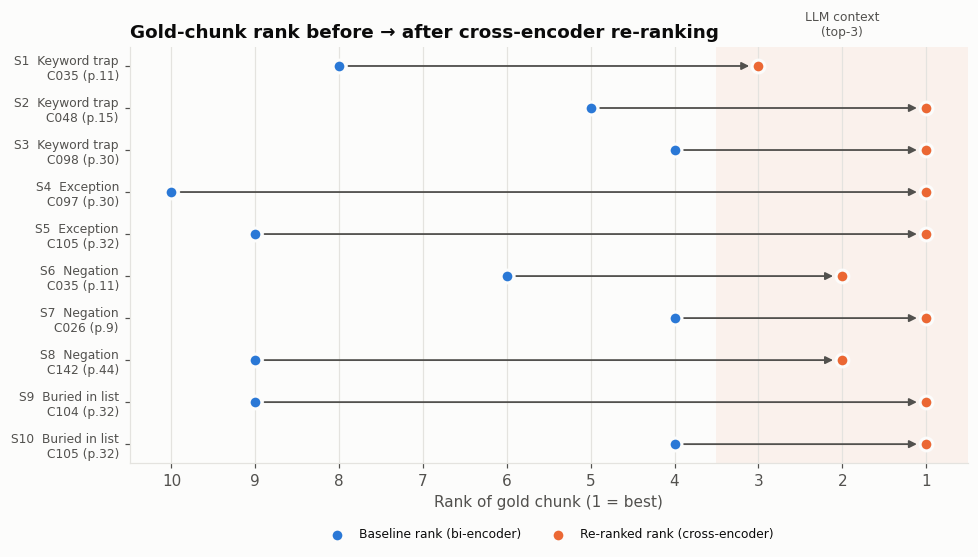

In [11]:
plot_df = shift_df[shift_df.id.str.startswith("S")].iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 5.2))
y = np.arange(len(plot_df))
for yi, (_, r) in zip(y, plot_df.iterrows()):
    ax.annotate("", xy=(r.reranked_rank, yi), xytext=(r.baseline_rank, yi),
                arrowprops=dict(arrowstyle="-|>", color=INK_2, lw=1.2, shrinkA=6, shrinkB=6))
ax.scatter(plot_df.baseline_rank, y, s=70, color=BASE_C, zorder=3, label="Baseline rank (bi-encoder)",
           edgecolor="#fcfcfb", linewidth=2)
ax.scatter(plot_df.reranked_rank, y, s=70, color=RERANK_C, zorder=3, label="Re-ranked rank (cross-encoder)",
           edgecolor="#fcfcfb", linewidth=2)
ax.axvspan(0.5, 3.5, color=RERANK_C, alpha=0.07, lw=0)
ax.text(2, len(plot_df) - 0.35, "LLM context\n(top-3)", ha="center", va="bottom", fontsize=8, color=INK_2)
ax.set_yticks(y, [f"{r.id}  {r.category}\n{r.gold_chunk} (p.{r.gold_page})" for _, r in plot_df.iterrows()],
              fontsize=8)
ax.set_xticks(range(1, 11)); ax.set_xlim(0.5, 10.5); ax.invert_xaxis()
ax.set_xlabel("Rank of gold chunk (1 = best)")
ax.set_title("Gold-chunk rank before → after cross-encoder re-ranking", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=8); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("figures/rank_shift.png", dpi=150); plt.show()

## 8. Answer 1 (baseline top-3) vs Answer 2 (re-ranked top-3)
Both answers use the identical prompt; only the 3 context chunks differ.
To grade them consistently, a separate **LLM-as-judge** call sees the question, the gold clause and one
answer (it is *not* told which pipeline produced it) and returns one label:
`CORRECT` · `PARTIAL` (true but omits an essential condition/exception) · `INCORRECT` (misstates the rule /
hallucinates) · `NOT_FOUND` (model refused - assigned by rule, no judge call). Every pair was then read by hand;
any label I disagree with is corrected in `MANUAL_REVIEW` with the reason.

In [12]:
JUDGE_PROMPT = """You grade answers about an insurance policy.
Question: {q}
Authoritative policy clause (ground truth): {gold}
Candidate answer: {a}

Extra details taken from other parts of the policy are acceptable unless they contradict the clause.
Labels:
CORRECT   - answer agrees with the clause, including its key condition/exception.
PARTIAL   - nothing false, but it omits an essential condition, exception or limit in the clause.
INCORRECT - answer contradicts the clause or states a rule/number not supported by it.
NOT_FOUND - answer says the information was not found.
Reply with JSON only: {{"label": "...", "reason": "<15 words>"}}"""

def gold_clause(t, width=700):
    # The text window around the gold marker, used as the judge's reference.
    i = min(t["gold_idx"])
    txt = chunks[i]["text"]
    m = t["gold"].split(";")[0].strip().lower()
    p = max(0, txt.lower().find(m) - 250)
    return txt[p:p + width]

def judge(q, gold, a):
    if a.lower().startswith("not found"):          # refusal -> label deterministically, no LLM needed
        return {"label": "NOT_FOUND", "reason": "model said the context lacks the answer"}
    raw, _, _ = call_llm(JUDGE_PROMPT.format(q=q, gold=gold, a=a), max_tokens=120,
                         model=JUDGE_MODEL, fallback=JUDGE_FALLBACK)
    m = re.search(r"\{.*\}", raw, re.S)
    try:
        return json.loads(m.group(0)) if m else {"label": "?", "reason": raw[:60]}
    except json.JSONDecodeError:
        return {"label": "?", "reason": raw[:60]}

answer_rows, llm_ms = [], []
for t in STRESS_TESTS:
    run = stress_runs[t["sid"]]
    a1, ms1, m1 = answer(t["query"], run["base_top3"])
    a2, ms2, m2 = answer(t["query"], run["rerank_top3"])
    llm_ms += [ms1, ms2]
    g = gold_clause(t)
    j1, j2 = judge(t["query"], g, a1), judge(t["query"], g, a2)
    answer_rows.append({"id": t["sid"], "category": t["category"], "query": t["query"],
                        "answer_1_baseline": a1, "grade_1": j1.get("label"), "why_1": j1.get("reason"),
                        "answer_2_reranked": a2, "grade_2": j2.get("label"), "why_2": j2.get("reason"),
                        "llm_ms_1": round(ms1), "llm_ms_2": round(ms2), "model": m1 if m1 == m2 else f"{m1}/{m2}"})

answers_df = pd.DataFrame(answer_rows)

# Manual review: every answer pair below was read by hand. Where the judge's label is wrong it is
# corrected here, with the reason, so the final grade is never silently different from the judge's.
MANUAL_REVIEW = {   # {(id, 1 or 2): (label, reason)}
    ("S2", 1): ("PARTIAL", "nothing it says is false, but it answers room-rent cover and misses the "
                           "Daily Cash for Shared Room benefit the question is about"),
    ("S7", 2): ("CORRECT", "judge reply was cut off (unparseable JSON); the answer gives both the 90 days-25 years "
                           "range and the financially-independent >18 rule"),
}
answers_df["final_1"], answers_df["final_2"] = answers_df.grade_1, answers_df.grade_2
answers_df["review_note"] = ""
for (sid, k), (label, note) in MANUAL_REVIEW.items():
    row = answers_df.id == sid
    answers_df.loc[row, f"final_{k}"] = label
    answers_df.loc[row, "review_note"] += f"A{k}: judge said {answers_df.loc[row, f'grade_{k}'].item()}, {note}. "
answers_df.to_csv("results/answers.csv", index=False)
answers_df[["id", "category", "grade_1", "final_1", "grade_2", "final_2", "review_note"]]

,id,category,grade_1,final_1,grade_2,final_2,review_note
0,S1,Keyword trap,NOT_FOUND,NOT_FOUND,CORRECT,CORRECT,
1,S2,Keyword trap,INCORRECT,PARTIAL,CORRECT,CORRECT,"A1: judge said INCORRECT, nothing it says is false, but it answers room-rent cover and misses the Daily Cash for Sha..."
2,S3,Keyword trap,NOT_FOUND,NOT_FOUND,CORRECT,CORRECT,
3,S4,Exception,NOT_FOUND,NOT_FOUND,CORRECT,CORRECT,
4,S5,Exception,NOT_FOUND,NOT_FOUND,CORRECT,CORRECT,
5,S6,Negation,INCORRECT,INCORRECT,CORRECT,CORRECT,
6,S7,Negation,NOT_FOUND,NOT_FOUND,?,CORRECT,"A2: judge said ?, judge reply was cut off (unparseable JSON); the answer gives both the 90 days-25 years range and t..."
7,S8,Negation,NOT_FOUND,NOT_FOUND,CORRECT,CORRECT,
8,S9,Buried in list,NOT_FOUND,NOT_FOUND,CORRECT,CORRECT,
9,S10,Buried in list,NOT_FOUND,NOT_FOUND,CORRECT,CORRECT,


In [13]:
# Print each pair in full, with the chunks each pipeline gave the LLM.
for (_, r), (_, s) in zip(answers_df.iterrows(), shift_df.iterrows()):
    print("=" * 110)
    print(f"{r.id} [{r.category}]  {r.query}")
    print(f"rank shift: {s.rank_shift}")
    print(f"\n  ANSWER 1  (baseline top-3: {s.baseline_top3})  ->  {r.final_1}  (judge: {r.why_1})")
    print("   ", r.answer_1_baseline.replace("\n", "\n    "))
    print(f"\n  ANSWER 2  (re-ranked top-3: {s.reranked_top3})  ->  {r.final_2}  (judge: {r.why_2})")
    print("   ", r.answer_2_reranked.replace("\n", "\n    "))

S1 [Keyword trap]  Will the policy pay for an ambulance to take me to the hospital?
rank shift: C035: #8 → #3

  ANSWER 1  (baseline top-3: C045, C023, C064)  ->  NOT_FOUND  (judge: Candidate claims the information is not found, but the clause explicitly covers it.)
    The policy defines an Ambulance as a motor vehicle equipped for transport and paramedical treatment [2]. However, the provided excerpts do not explicitly state whether the policy covers the costs of ambulance services. While "Emergency Air Ambulance" is mentioned as an optional cover [1], the details regarding coverage for standard ambulance transport are not found in the provided context.

  ANSWER 2  (re-ranked top-3: C023, C046, C035)  ->  CORRECT  (judge: Accurately confirms road ambulance coverage for emergency transport to the nearest hospital.)
    Yes, the policy covers road ambulance expenses for transfers to the nearest hospital for emergency care, between hospitals, or from a hospital to home within the same 

In [14]:
order = ["CORRECT", "PARTIAL", "INCORRECT", "NOT_FOUND"]
s_only = answers_df[answers_df.id.str.startswith("S")]
grade_tab = pd.DataFrame({"Answer 1 (baseline)": s_only.final_1.value_counts().reindex(order, fill_value=0),
                          "Answer 2 (re-ranked)": s_only.final_2.value_counts().reindex(order, fill_value=0)})
grade_tab.to_csv("results/answer_grades.csv")
print(f"Stress queries S1-S{len(s_only)} (final grades = judge, corrected by manual review where noted):")
grade_tab

Stress queries S1-S10 (final grades = judge, corrected by manual review where noted):


,Answer 1 (baseline),Answer 2 (re-ranked)
CORRECT,0,10
PARTIAL,1,0
INCORRECT,1,0
NOT_FOUND,8,0


## 9. Aggregate evaluation on all hand-labelled queries
The stress tests show *that* failures happen; this section measures *how often*. `data/eval_queries.csv`
holds plain-language questions written while reading the policy, each with one or more verbatim gold
markers (`;`-separated, so every clause that answers the question counts; the stress queries are included). Metrics are computed from the gold chunk's rank:

* **Hit@1 / Hit@3** — gold chunk at rank 1 / in the top-3 given to the LLM
* **MRR@10** — mean of 1/rank (0 if not in top-10)
* **Recall@10** — gold anywhere in the 10 candidates (identical for both — it is the re-ranker's ceiling)

In [15]:
eval_df = pd.read_csv("data/eval_queries.csv")
eval_rows, eval_runs = [], {}
for _, q in eval_df.iterrows():
    g = gold_idx(q.gold_markers)
    run = run_retrieval(q.query)
    eval_runs[q.qid] = (run, g)
    rb, rc = first_rank(run["top10"], g, "bi_rank"), first_rank(run["reranked"], g, "ce_rank")
    eval_rows.append({"qid": q.qid, "query": q.query, "n_gold_chunks": len(g),
                      "baseline_rank": rb, "reranked_rank": rc, **run["timing"]})
er = pd.DataFrame(eval_rows)

def metrics(ranks):
    r = ranks.fillna(np.inf)
    return {"Hit@1": (r <= 1).mean(), "Hit@3": (r <= 3).mean(),
            "MRR@10": np.where(r <= 10, 1 / r, 0).mean(), "Recall@10": (r <= 10).mean()}

metric_df = pd.DataFrame({"Baseline (bi-encoder)": metrics(er.baseline_rank),
                          "Re-ranked (cross-encoder)": metrics(er.reranked_rank)}).round(3)
in10 = er.dropna(subset=["baseline_rank"])
moves = pd.Series({
    "queries": len(er),
    "gold in top-10 (re-ranker can act)": len(in10),
    "promoted INTO top-3 (wins)": int(((in10.baseline_rank > 3) & (in10.reranked_rank <= 3)).sum()),
    "pushed OUT of top-3 (losses)": int(((in10.baseline_rank <= 3) & (in10.reranked_rank > 3)).sum()),
    "rank improved": int((in10.reranked_rank < in10.baseline_rank).sum()),
    "rank unchanged": int((in10.reranked_rank == in10.baseline_rank).sum()),
    "rank worsened": int((in10.reranked_rank > in10.baseline_rank).sum()),
})
er.to_csv("results/eval_per_query.csv", index=False)
metric_df.to_csv("results/eval_metrics.csv")
moves.to_csv("results/eval_moves.csv", header=["count"])
display(metric_df)
moves

,Baseline (bi-encoder),Re-ranked (cross-encoder)
Hit@1,0.368,0.421
Hit@3,0.561,0.605
MRR@10,0.480,0.523
Recall@10,0.728,0.728


queries                               114
gold in top-10 (re-ranker can act)     83
promoted INTO top-3 (wins)             11
pushed OUT of top-3 (losses)            6
rank improved                          25
rank unchanged                         40
rank worsened                          18
dtype: int64

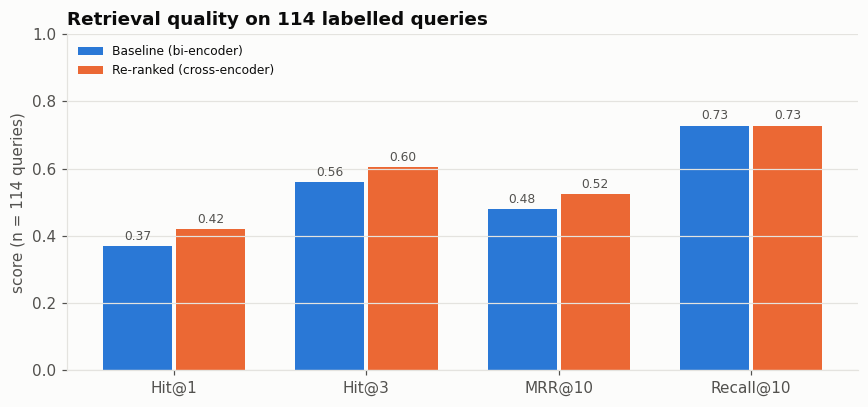

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.8))
names = list(metric_df.index); x = np.arange(len(names)); w = 0.36
b1 = ax.bar(x - w / 2 - 0.01, metric_df.iloc[:, 0], w, color=BASE_C, label=metric_df.columns[0])
b2 = ax.bar(x + w / 2 + 0.01, metric_df.iloc[:, 1], w, color=RERANK_C, label=metric_df.columns[1])
for bars in (b1, b2):
    ax.bar_label(bars, fmt="%.2f", fontsize=8, color=INK_2, padding=2)
ax.set_xticks(x, names); ax.set_ylim(0, 1); ax.set_ylabel(f"score (n = {len(er)} queries)")
ax.set_title(f"Retrieval quality on {len(er)} labelled queries", loc="left"); ax.legend(fontsize=8, loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig("figures/eval_metrics.png", dpi=150); plt.show()

## 10. Why the cross-encoder separates better: score distributions
For every (query, candidate) pair in the evaluation set's top-10 candidate lists we have a bi-encoder cosine and a
cross-encoder score, and we know whether the candidate is gold. **AUC** = probability that a random gold
candidate scores higher than a random non-gold candidate *from the same top-10* (0.5 = no separation).

In [17]:
pair_rows = []
for qid, (run, g) in eval_runs.items():
    for c in run["reranked"]:
        pair_rows.append({"qid": qid, "gold": c["idx"] in g, "bi": c["bi_score"], "ce": c["ce_score"]})
pairs = pd.DataFrame(pair_rows)

def within_query_auc(df, col):
    # Mann-Whitney AUC computed inside each query's top-10, averaged over queries that have both classes.
    aucs = []
    for _, d in df.groupby("qid"):
        pos, neg = d[d.gold][col].values, d[~d.gold][col].values
        if len(pos) and len(neg):
            aucs.append(((pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean()))
    return np.mean(aucs), len(aucs)

auc_bi, n_auc = within_query_auc(pairs, "bi")
auc_ce, _ = within_query_auc(pairs, "ce")
spread = pairs.groupby("qid").agg(bi_range=("bi", lambda s: s.max() - s.min()),
                                  ce_range=("ce", lambda s: s.max() - s.min())).mean()
sep_df = pd.DataFrame({"within-top-10 AUC": [auc_bi, auc_ce],
                       "mean score range inside a top-10": [spread.bi_range, spread.ce_range]},
                      index=["bi-encoder cosine", "cross-encoder logit"]).round(3)
sep_df.to_csv("results/score_separation.csv")
print(f"AUC over {n_auc} queries whose top-10 contains both gold and non-gold chunks")
sep_df

AUC over 83 queries whose top-10 contains both gold and non-gold chunks


,within-top-10 AUC,mean score range inside a top-10
bi-encoder cosine,0.774,0.121
cross-encoder logit,0.856,8.434


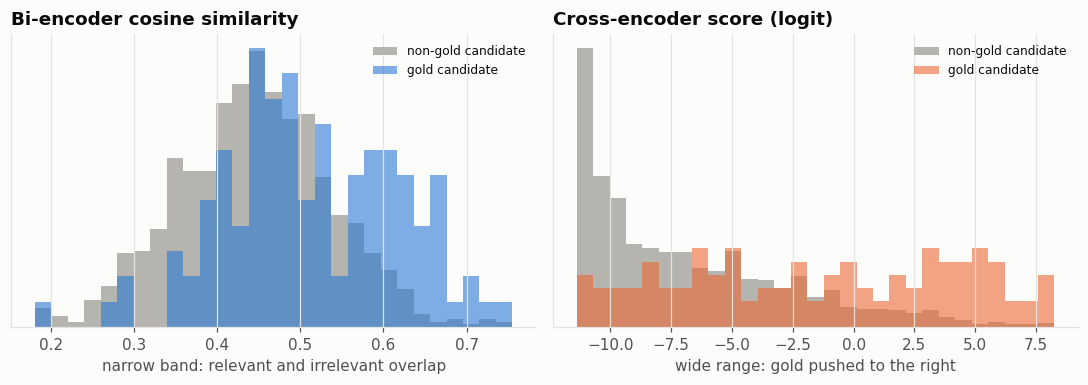

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, title in [(axes[0], "bi", "Bi-encoder cosine similarity"), (axes[1], "ce", "Cross-encoder score (logit)")]:
    bins = np.linspace(pairs[col].min(), pairs[col].max(), 30)
    ax.hist(pairs[~pairs.gold][col], bins=bins, color="#b5b4ae", label="non-gold candidate", density=True)
    ax.hist(pairs[pairs.gold][col], bins=bins, color=RERANK_C if col == "ce" else BASE_C, alpha=0.6,
            label="gold candidate", density=True)
    ax.set_title(title, loc="left"); ax.set_yticks([]); ax.grid(axis="y", visible=False)
    ax.legend(fontsize=8)
axes[0].set_xlabel("narrow band: relevant and irrelevant overlap")
axes[1].set_xlabel("wide range: gold pushed to the right")
plt.tight_layout(); plt.savefig("figures/score_distributions.png", dpi=150); plt.show()

## 11. Latency profiling
Retrieval stages are timed over every evaluation query (CPU, 4 torch threads, models already warm). LLM time
comes from the Answer 1 / Answer 2 generation calls in Section 8 (network + Gemini inference).

In [19]:
def summarise(ms):
    ms = np.asarray(ms)
    return {"mean_ms": ms.mean(), "median_ms": np.median(ms), "p95_ms": np.percentile(ms, 95), "std_ms": ms.std()}

stage = {
    "Query embedding (bi-encoder)":    er.embed_ms,
    "FAISS search (176 vectors)":      er.search_ms,
    "Cross-encoder re-rank (10 pairs)": er.rerank_ms,
    "LLM generation (Gemini)":          pd.Series(llm_ms),
}
lat = pd.DataFrame({k: summarise(v) for k, v in stage.items()}).T.round(2)
p1_ret = er.embed_ms + er.search_ms
p2_ret = p1_ret + er.rerank_ms
llm_mean = np.mean(llm_ms)
totals = pd.DataFrame({
    "Pipeline 1 – Baseline": {"retrieval_ms (mean)": p1_ret.mean(), "retrieval_ms (p95)": np.percentile(p1_ret, 95),
                              "end_to_end_ms (mean, incl. LLM)": p1_ret.mean() + llm_mean},
    "Pipeline 2 – Re-rank":  {"retrieval_ms (mean)": p2_ret.mean(), "retrieval_ms (p95)": np.percentile(p2_ret, 95),
                              "end_to_end_ms (mean, incl. LLM)": p2_ret.mean() + llm_mean},
}).T.round(1)
totals["retrieval slowdown"] = (totals["retrieval_ms (mean)"] / totals["retrieval_ms (mean)"].iloc[0]).round(1).astype(str) + "×"
totals["end-to-end overhead"] = ((totals["end_to_end_ms (mean, incl. LLM)"] /
                                  totals["end_to_end_ms (mean, incl. LLM)"].iloc[0] - 1) * 100).round(1).astype(str) + "%"
lat.to_csv("results/latency_stages.csv"); totals.to_csv("results/latency_totals.csv")
display(lat); totals

,mean_ms,median_ms,p95_ms,std_ms
Query embedding (bi-encoder),9.44,10.44,11.55,2.32
FAISS search (176 vectors),0.07,0.08,0.08,0.01
Cross-encoder re-rank (10 pairs),304.36,340.29,368.61,82.33
LLM generation (Gemini),1473.29,1310.90,3153.37,745.27


,retrieval_ms (mean),retrieval_ms (p95),"end_to_end_ms (mean, incl. LLM)",retrieval slowdown,end-to-end overhead
Pipeline 1 – Baseline,9.5,11.6,1482.8,1.0×,0.0%
Pipeline 2 – Re-rank,313.9,379.9,1787.2,33.0×,20.5%


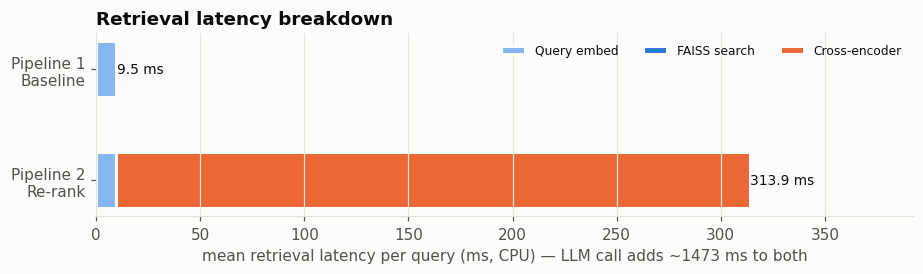

In [20]:
fig, ax = plt.subplots(figsize=(8.5, 2.6))
segs = [("Query embed", er.embed_ms.mean(), "#86b6ef"), ("FAISS search", er.search_ms.mean(), BASE_C),
        ("Cross-encoder", er.rerank_ms.mean(), RERANK_C)]
for row, include_ce in [(1, False), (0, True)]:
    left = 0
    for name, v, col in segs:
        if name == "Cross-encoder" and not include_ce:
            continue
        ax.barh(row, v, left=left, color=col, height=0.5, edgecolor="#fcfcfb", linewidth=2,
                label=name if row == 0 else None)
        left += v
    ax.text(left + 0.4, row, f"{left:.1f} ms", va="center", fontsize=9, color=INK)
ax.set_yticks([1, 0], ["Pipeline 1\nBaseline", "Pipeline 2\nRe-rank"])
ax.set_xlabel("mean retrieval latency per query (ms, CPU) — LLM call adds ~%.0f ms to both" % llm_mean)
ax.set_title("Retrieval latency breakdown", loc="left"); ax.legend(fontsize=8, ncol=3, loc="upper right")
ax.grid(axis="y", visible=False); ax.set_xlim(0, (er.embed_ms + er.search_ms + er.rerank_ms).mean() * 1.25)
plt.tight_layout(); plt.savefig("figures/latency.png", dpi=150); plt.show()

## 12. Scaling: why not run the cross-encoder over the whole collection?
Three measurements:
1. **Cross-encoder cost vs number of chunks scored** (10 → all 176) — it is linear: one full transformer
   forward pass per (query, chunk) pair, nothing can be pre-computed because the query is part of the input.
2. **Re-rank depth ablation** — re-ranking 20, 50 or *all* 176 chunks: what does the extra cost buy?
3. **Bi-encoder search cost vs corpus size** (synthetic 384-d vectors up to 500k) — the corpus side is
   embedded once, offline; per query only a dot-product search remains.

> **Note on absolute timings.** This runs on a laptop CPU (i7-1360P) whose speed changes with thermal state;
> across development runs the cross-encoder cost varied between ~15 and ~35 ms per pair. Absolute numbers are
> therefore indicative. What the argument relies on is the *shape*: the cost per pair is constant as the number
> of chunks grows (linear scaling). Projections use the Section-11 median from the same run.

In [21]:
# A laptop CPU throttles under sustained load, so each size is timed 3x per query and the MINIMUM is kept
# (standard micro-benchmark practice: the minimum is the run least disturbed by throttling/background work).
probe_q = [t["query"] for t in STRESS_TESTS[:5]]
ce_scale = []
for n in [10, 25, 50, 100, len(chunks)]:
    per_q = []
    for q in probe_q:
        texts = [(q, c["text"]) for c in chunks[:n]]
        reps = []
        for _ in range(3):
            t0 = time.perf_counter(); cross_encoder.predict(texts, batch_size=16); reps.append(time.perf_counter() - t0)
        per_q.append(min(reps))
    ce_scale.append({"chunks_scored": n, "ce_ms_per_query": np.median(per_q) * 1e3})
ce_scale = pd.DataFrame(ce_scale)
ce_scale["ms_per_pair"] = (ce_scale.ce_ms_per_query / ce_scale.chunks_scored).round(2)
# Cost per pair used for projections = Pipeline-2 measurement from Section 11 (114 real queries, 10 pairs each).
per_pair_ms = er.rerank_ms.median() / TOP_K_RETRIEVE
print(f"per-pair cost used for projections: {per_pair_ms:.1f} ms (Section 11 median / 10)")
ce_scale.round(1)

per-pair cost used for projections: 34.0 ms (Section 11 median / 10)


,chunks_scored,ce_ms_per_query,ms_per_pair
0,10,335.7,33.6
1,25,856.4,34.3
2,50,1687.1,33.7
3,100,3399.4,34.0
4,176,5909.1,33.6


In [22]:
# Re-rank depth ablation on the labelled queries: candidates from the bi-encoder top-k, then cross-encoder.
depth_rows = []
for k in [3, 5, 10, 20, 50, len(chunks)]:
    rb, rc, ms = [], [], []
    for _, q in eval_df.iterrows():
        g = gold_idx(q.gold_markers)
        cands, _ = retrieve_baseline(q.query, k=k)
        rr, t = rerank(q.query, cands)
        rb.append(first_rank(cands, g, "bi_rank")); rc.append(first_rank(rr, g, "ce_rank")); ms.append(t["rerank_ms"])
    rb, rc = pd.Series(rb, dtype=float).fillna(np.inf), pd.Series(rc, dtype=float).fillna(np.inf)
    depth_rows.append({"rerank_depth_k": k, f"Recall@k": (rb <= k).mean(), "Hit@3 after re-rank": (rc <= 3).mean(),
                       "MRR after re-rank": np.where(np.isfinite(rc), 1 / rc, 0).mean(),
                       "CE ms/query (k × per-pair cost)": k * per_pair_ms})
depth_df = pd.DataFrame(depth_rows).round(3)
depth_df.to_csv("results/rerank_depth_ablation.csv", index=False)
depth_df

,rerank_depth_k,Recall@k,Hit@3 after re-rank,MRR after re-rank,CE ms/query (k × per-pair cost)
0,3,0.561,0.561,0.466,102.087
1,5,0.614,0.596,0.497,170.145
2,10,0.728,0.605,0.523,340.291
3,20,0.842,0.649,0.547,680.582
4,50,0.930,0.658,0.556,1701.455
5,176,1.000,0.649,0.560,5989.122


In [23]:
# Bi-encoder side: exact FAISS search time vs corpus size (synthetic normalised 384-d vectors).
rng = np.random.default_rng(0)
faiss_rows = []
for n in [len(chunks), 10_000, 100_000, 500_000]:
    xb = rng.standard_normal((n, 384), dtype=np.float32); faiss.normalize_L2(xb)
    ix = faiss.IndexFlatIP(384); ix.add(xb)
    q = rng.standard_normal((1, 384), dtype=np.float32); faiss.normalize_L2(q)
    ix.search(q, 10)
    ts = []
    for _ in range(20):
        t0 = time.perf_counter(); ix.search(q, 10); ts.append(time.perf_counter() - t0)
    faiss_rows.append({"corpus_chunks": n, "faiss_flat_ms": np.median(ts) * 1e3})
    del xb, ix
faiss_df = pd.DataFrame(faiss_rows)
faiss_ms_per_vec = np.polyfit(faiss_df.corpus_chunks, faiss_df.faiss_flat_ms, 1)[0]

# Extrapolate both to realistic corpus sizes (linear, measured on this CPU).
embed_ms = er.embed_ms.mean()          # query embedding: constant, independent of corpus size
fmt_t = lambda ms: f"{ms:.1f} ms" if ms < 1e3 else f"{ms / 1e3:,.1f} s" if ms < 3.6e6 else f"{ms / 3.6e6:,.1f} h"
proj = []
for n in [len(chunks), 10_000, 100_000, 1_000_000, 10_000_000]:
    p1 = embed_ms + max(n * faiss_ms_per_vec, faiss_df.faiss_flat_ms.min())   # Pipeline 1 retrieval
    p2 = p1 + 10 * per_pair_ms                                                  # Pipeline 2 retrieval
    ce_all = n * per_pair_ms                                                    # CE over every chunk
    proj.append({"corpus_chunks": f"{n:,}", "P1: embed + flat search": fmt_t(p1),
                 "P2: P1 + CE on top-10": fmt_t(p2), "CE on ALL chunks": fmt_t(ce_all),
                 "CE-all ÷ P2": f"{ce_all / p2:,.0f}×"})
proj_df = pd.DataFrame(proj)
faiss_df.to_csv("results/faiss_scaling.csv", index=False); ce_scale.to_csv("results/ce_scaling.csv", index=False)
proj_df.to_csv("results/scaling_projection.csv", index=False)
print(f"Measured: cross-encoder ≈ {per_pair_ms:.2f} ms per (query, chunk) pair; "
      f"flat FAISS ≈ {faiss_ms_per_vec * 1e6:.1f} ms per million vectors")
display(faiss_df.round(2)); proj_df

Measured: cross-encoder ≈ 34.03 ms per (query, chunk) pair; flat FAISS ≈ 70.4 ms per million vectors


,corpus_chunks,faiss_flat_ms
0,176,0.02
1,10000,0.65
2,100000,7.28
3,500000,35.23


,corpus_chunks,P1: embed + flat search,P2: P1 + CE on top-10,CE on ALL chunks,CE-all ÷ P2
0,176,9.5 ms,349.7 ms,6.0 s,17×
1,"10,000",10.1 ms,350.4 ms,340.3 s,971×
2,"100,000",16.5 ms,356.8 ms,"3,402.9 s","9,538×"
3,"1,000,000",79.9 ms,420.2 ms,9.5 h,"80,992×"
4,"10,000,000",713.7 ms,1.1 s,94.5 h,"322,863×"


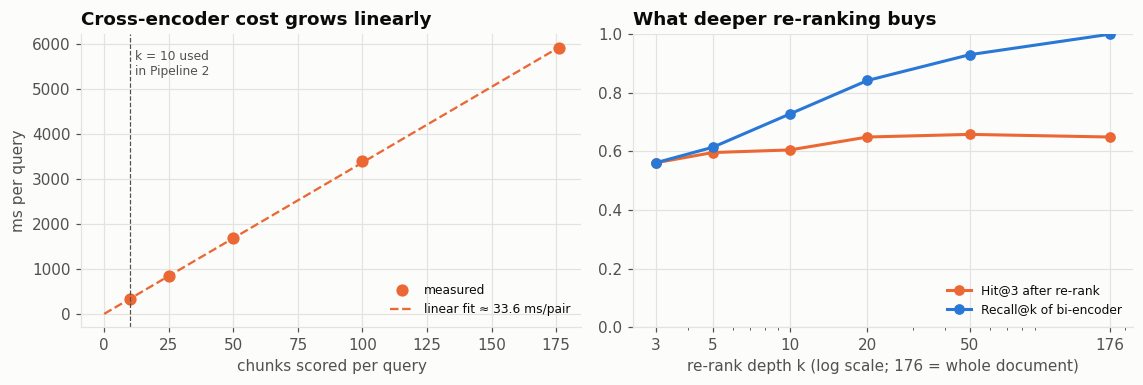

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax = axes[0]
ax.plot(ce_scale.chunks_scored, ce_scale.ce_ms_per_query, "o", color=RERANK_C, ms=7, label="measured")
fit = np.polyfit(ce_scale.chunks_scored, ce_scale.ce_ms_per_query, 1)
xs = np.array([0, ce_scale.chunks_scored.max()])
ax.plot(xs, np.polyval(fit, xs), "--", color=RERANK_C, lw=1.5, label=f"linear fit ≈ {fit[0]:.1f} ms/pair")
ax.legend(fontsize=8, loc="lower right")
ax.axvline(10, color=INK_2, lw=0.8, ls="--"); ax.text(12, ce_scale.ce_ms_per_query.max() * 0.9, "k = 10 used\nin Pipeline 2", fontsize=8, color=INK_2)
ax.set_xlabel("chunks scored per query"); ax.set_ylabel("ms per query")
ax.set_title("Cross-encoder cost grows linearly", loc="left")
ax = axes[1]
ax.plot(depth_df.rerank_depth_k, depth_df["Hit@3 after re-rank"], "-o", color=RERANK_C, lw=2, ms=6, label="Hit@3 after re-rank")
ax.plot(depth_df.rerank_depth_k, depth_df["Recall@k"], "-o", color=BASE_C, lw=2, ms=6, label="Recall@k of bi-encoder")
ax.set_xscale("log"); ax.set_xticks(depth_df.rerank_depth_k, [str(k) for k in depth_df.rerank_depth_k])
ax.set_ylim(0, 1); ax.set_xlabel("re-rank depth k (log scale; 176 = whole document)")
ax.set_title("What deeper re-ranking buys", loc="left"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig("figures/scaling.png", dpi=150); plt.show()

## 13. Limitations observed
* **Recall ceiling (L2 and others):** the re-ranker only reorders the 10 candidates. "Hernia" exists only in
  the jumbled 24-month waiting-period table, which the bi-encoder ranks far outside the top-10, so Pipeline 2
  cannot recover it. Recall@10 is the upper bound for Pipeline 2's Hit@3.
* **Regressions (L1):** the MS-MARCO cross-encoder was trained on web-search passages. For "26-year-old son" it
  prefers the Cumulative-Bonus / Plus-Benefit renewal rules (which literally mention "family floater", "split"
  and "child attaining the Age of 25") over the Family-Members definition that actually answers the question.
* **Table-heavy pages** (Annexure C plan chart, waiting-period disease grid) extract as jumbled text and are
  hard for both models.
* **Grading** uses an LLM judge plus manual spot-checks on 11 queries — indicative, not a benchmark.

In [25]:
lim = shift_df[shift_df.id.str.startswith("L")][["id", "category", "query", "rank_shift", "baseline_top3", "reranked_top3"]]
display(lim)
print("All regressions in the evaluation set (gold in baseline top-3, pushed out by the cross-encoder):")
er[(er.baseline_rank <= 3) & (er.reranked_rank > 3)][["qid", "query", "baseline_rank", "reranked_rank"]]

,id,category,query,rank_shift,baseline_top3,reranked_top3
10,L1,Limitation: CE regression,Can my 26 year old son stay on the family floater policy?,C026: #3 → #9,"C052, C042, C026","C055, C052, C043"
11,L2,Limitation: recall ceiling,Is a hernia operation covered right away?,C095: #35 → not in top-10,"C098, C096, C045","C045, C097, C094"


All regressions in the evaluation set (gold in baseline top-3, pushed out by the cross-encoder):


,qid,query,baseline_rank,reranked_rank
14,Q015,Can my 26 year old son stay on the family floater policy?,3.0,9.0
26,Q027,Can the insurer reject my claim after 5 years for not disclosing a disease?,2.0,4.0
38,Q039,Is my claim paid if I am admitted to hospital only for tests?,3.0,7.0
74,Q075,How many days after discharge are post-hospitalization expenses covered?,2.0,4.0
78,Q079,Which sports injuries are not covered?,1.0,5.0
102,Q103,Is a C-section delivery covered?,1.0,5.0


## 14. Summary

In [26]:
wins = shift_df[(~shift_df.in_top3_baseline) & (shift_df.in_top3_reranked)]
summary = {
    "chunks": len(chunks),
    "stress queries where re-ranking restored the gold chunk into top-3": f"{len(wins)} / {len(shift_df[shift_df.id.str.startswith('S')])}",
    f"Hit@3 baseline -> re-ranked ({len(er)} queries)": f"{metric_df.loc['Hit@3'].iloc[0]:.2f} -> {metric_df.loc['Hit@3'].iloc[1]:.2f}",
    "MRR@10 baseline -> re-ranked": f"{metric_df.loc['MRR@10'].iloc[0]:.3f} -> {metric_df.loc['MRR@10'].iloc[1]:.3f}",
    "Recall@10 (ceiling for both)": f"{metric_df.loc['Recall@10'].iloc[0]:.2f}",
    "wins / losses (into / out of top-3)": f"{moves['promoted INTO top-3 (wins)']} / {moves['pushed OUT of top-3 (losses)']}",
    "Answer grades, stress queries, baseline (C/P/I/NF)": "/".join(str(v) for v in grade_tab.iloc[:, 0]),
    "Answer grades, stress queries, re-ranked (C/P/I/NF)": "/".join(str(v) for v in grade_tab.iloc[:, 1]),
    "retrieval latency P1 -> P2 (mean ms)": f"{p1_ret.mean():.1f} -> {p2_ret.mean():.1f}",
    "LLM latency (mean ms)": f"{llm_mean:.0f}",
    "cross-encoder ms per pair": f"{per_pair_ms:.2f}",
}
json.dump(summary, open("results/summary.json", "w"), indent=2, ensure_ascii=False)
pd.Series(summary, name="value").to_frame()

,value
chunks,176
stress queries where re-ranking restored the gold chunk into top-3,10 / 10
Hit@3 baseline -> re-ranked (114 queries),0.56 -> 0.60
MRR@10 baseline -> re-ranked,0.480 -> 0.523
Recall@10 (ceiling for both),0.73
wins / losses (into / out of top-3),11 / 6
"Answer grades, stress queries, baseline (C/P/I/NF)",0/1/1/8
"Answer grades, stress queries, re-ranked (C/P/I/NF)",10/0/0/0
retrieval latency P1 -> P2 (mean ms),9.5 -> 313.9
LLM latency (mean ms),1473
